# EDA (Exploratory Data Analysis) of the Abalone dataset

Goal: understand the data before predicting the age of an abalone (its number of `Rings`) from physical measurements.

# Imports

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 500)
sns.set_theme(style="whitegrid")

# Data

In [2]:
df = pd.read_csv("../data/abalone.csv")
df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   str    
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 297.9 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Length,4177.0,0.523992,0.120093,0.0750,0.4500,0.5450,0.615,0.8150
Diameter,4177.0,0.407881,0.099240,0.0550,0.3500,0.4250,0.480,0.6500
Height,4177.0,0.139516,0.041827,0.0000,0.1150,0.1400,0.165,1.1300
Whole weight,4177.0,0.828742,0.490389,0.0020,0.4415,0.7995,1.153,2.8255
Shucked weight,4177.0,0.359367,0.221963,0.0010,0.1860,0.3360,0.502,1.4880
Viscera weight,4177.0,0.180594,0.109614,0.0005,0.0935,0.1710,0.253,0.7600
Shell weight,4177.0,0.238831,0.139203,0.0015,0.1300,0.2340,0.329,1.0050
Rings,4177.0,9.933684,3.224169,1.0000,8.0000,9.0000,11.000,29.0000


In [5]:
print("Missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())

Missing values: 0
Duplicated rows: 0


# EDA

## Target: `Rings`

Age in years is roughly `Rings + 1.5`, `Rings` is predicted directly.

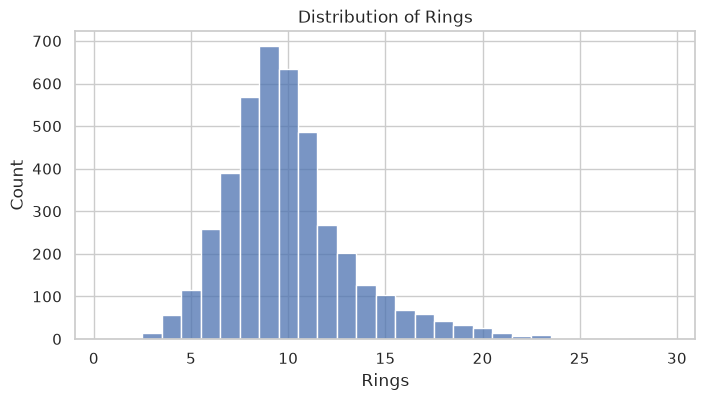

Skewness: 1.11


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["Rings"], discrete=True, ax=ax)
ax.set_title("Distribution of Rings")
plt.show()

print("Skewness:", round(df["Rings"].skew(), 2))

## Numerical features

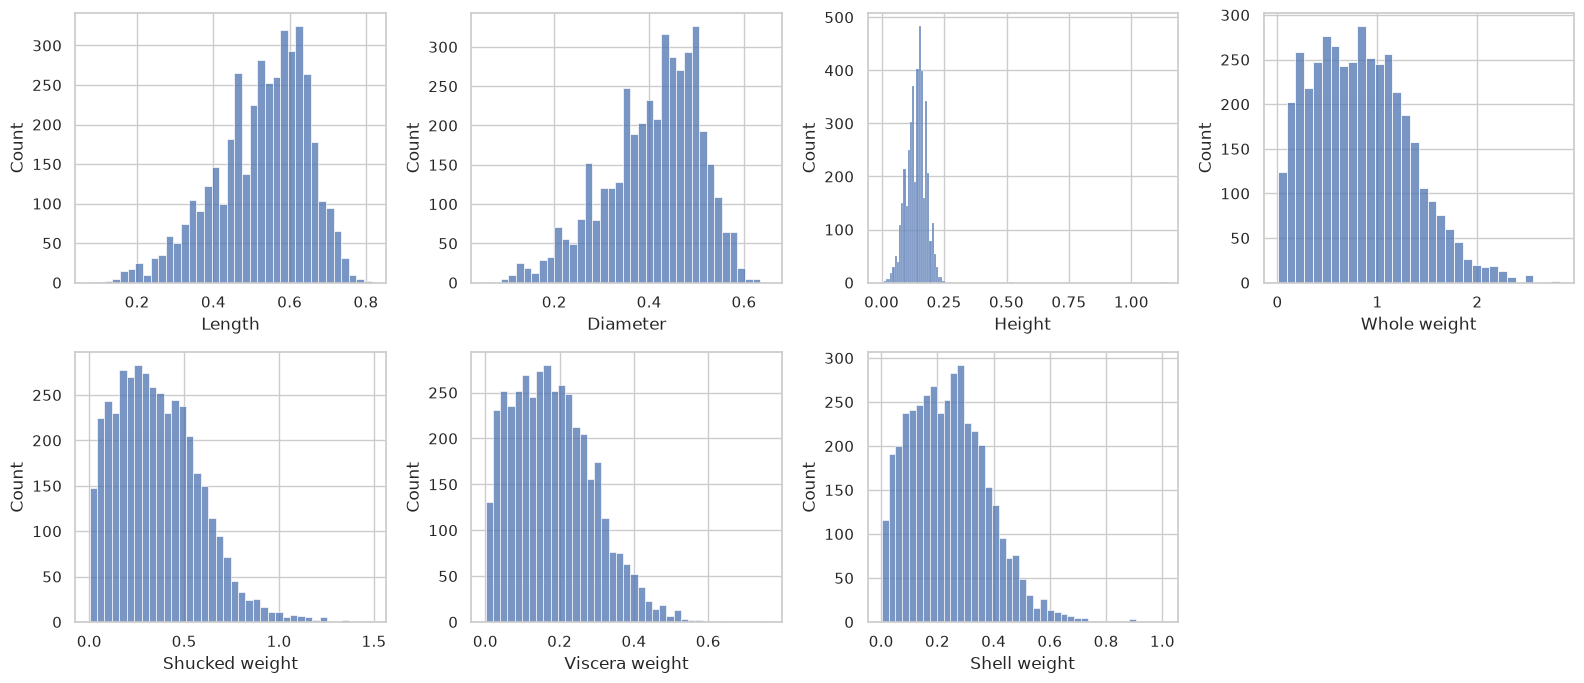

In [7]:
numerical_features = df.columns.drop(["Sex", "Rings"])

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, feature in zip(axes.flat, numerical_features):
    sns.histplot(df[feature], ax=ax)
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

## `Sex` categories

M = male, F = female, I = infant.

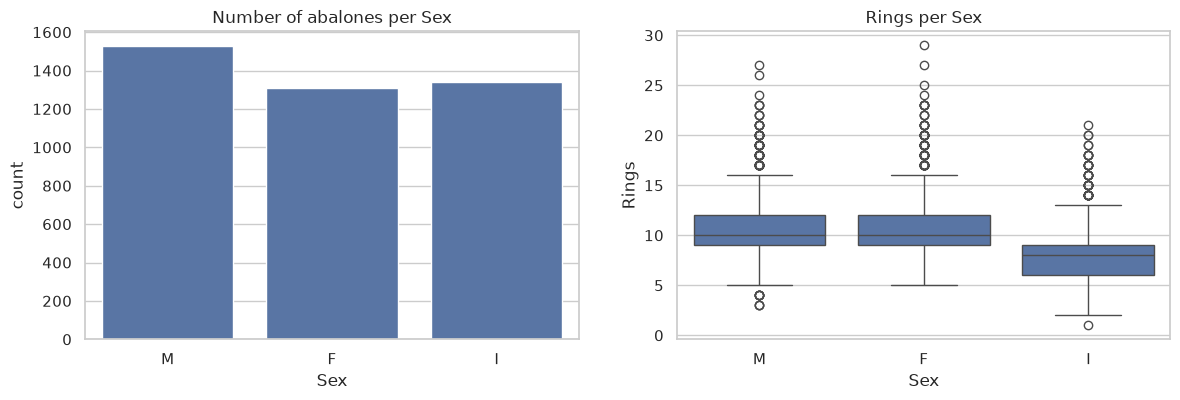

,mean,median,std
Sex,,,
F,11.129304,10.0,3.104256
I,7.890462,8.0,2.511554
M,10.705497,10.0,3.026349


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=df, x="Sex", order=["M", "F", "I"], ax=axes[0])
axes[0].set_title("Number of abalones per Sex")
sns.boxplot(data=df, x="Sex", y="Rings", order=["M", "F", "I"], ax=axes[1])
axes[1].set_title("Rings per Sex")
plt.show()

df.groupby("Sex")["Rings"].agg(["mean", "median", "std"])

## Correlations

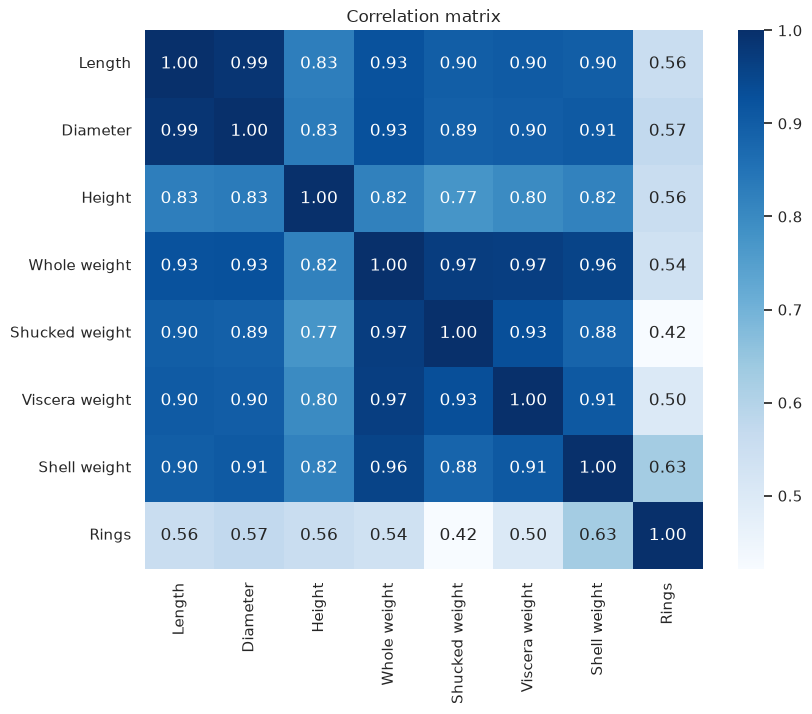

In [9]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set_title("Correlation matrix")
plt.show()

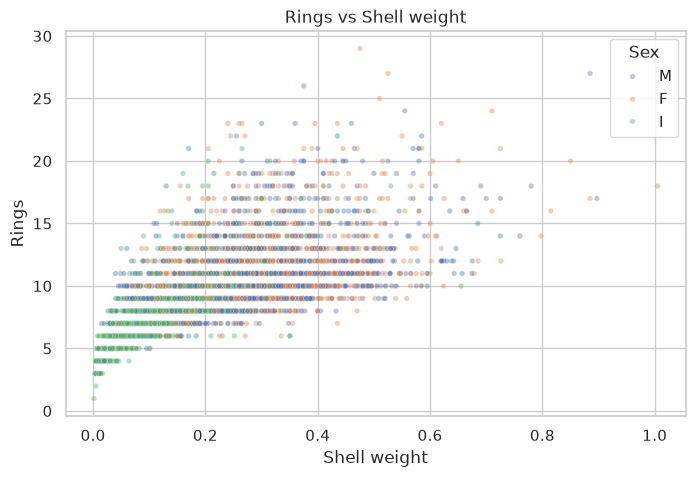

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="Shell weight", y="Rings", hue="Sex", alpha=0.4, s=15, ax=ax)
ax.set_title("Rings vs Shell weight")
plt.show()

## Data quality

In [11]:
print("Height == 0:", (df["Height"] == 0).sum())
df.nlargest(3, "Height")

Height == 0: 2


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
2051,F,0.455,0.355,1.130,0.594,0.3320,0.1160,0.1335,8
1417,M,0.705,0.565,0.515,2.210,1.1075,0.4865,0.5120,10
1428,F,0.815,0.650,0.250,2.255,0.8905,0.4200,0.7975,14


In [12]:
parts = df[["Shucked weight", "Viscera weight", "Shell weight"]].sum(axis=1)
print("Whole weight < sum of its parts:", (df["Whole weight"] < parts).sum())

Whole weight < sum of its parts: 155


# Conclusions

- **The data is clean**: It contains 4,177 rows, 8 features + the target, no missing values and no duplicates.
- **Target**: `Rings` ranges from 1 to 29, centred around 9-10 and is right-skewed. The few very old abalones will be hard to predict.
- **Sex**: the three categories are balanced. Infants have fewer rings than males and females. `Sex` is categorical and it is one-hot encoded.
- **Correlations**: every measurement is positively correlated with `Rings`, `Shell weight` the most (0.63). The measurements are also very correlated with each other (> 0.9) because they all describe the size of the abalone. The link with `Rings` flattens for large abalones: once grown, size says little about age.
- **Data quality**: 2 rows have `Height = 0` and 2 rows have an extreme `Height` (1.13 and 0.515). 155 rows have a `Whole weight` smaller than the sum of its parts, probably measurement noise. These are few rows, so we keep them for the first model.